<a href="https://colab.research.google.com/github/alessiomodonesi/Python-Exercises/blob/main/AI_MSc/lab3/Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3: Bayesian Network Design & Inference with pyAgrum

In this lab we use [**pyAgrum**](https://pyagrum.readthedocs.io), a Python library for probabilistic graphical models.

- **Part 1 — Bayesian network design**: we build a network (structure and conditional probability tables) and read its independencies.
- **Part 2 — Bayesian network inference**: we answer queries on the network with the main families of inference algorithms. We follow the taxonomy of the tutorial [*Probabilistic Graphical Models: A Concise Tutorial*](https://arxiv.org/abs/2507.17116) (Maasch, Neiswanger, Ermon, Kuleshov, 2025), chapters 4 and 5:

| family | pyAgrum engines used in this notebook |
|---|---|
| **exact inference** | `VariableElimination`, `ShaferShenoyInference` and `LazyPropagation` (junction tree) |
| **approximate inference (sampling)** | forward sampling, rejection sampling (`MonteCarloSampling`), likelihood weighting (`WeightedSampling`), Gibbs sampling (`GibbsSampling`) |

In [42]:
%pip install -q pyagrum

Note: you may need to restart the kernel to use updated packages.


In [43]:
import itertools, math, random, shutil, time
import matplotlib.pyplot as plt
import pyagrum as gum
import pyagrum.lib.notebook as gnb      # drawings of networks, CPTs and posteriors

random.seed(0)
gum.initRandom(0)                        # same random samples every time
print("pyAgrum", gum.__version__)

# pyAgrum draws the networks with Graphviz ("dot"), already installed on Colab.
HAS_GRAPHVIZ = shutil.which("dot") is not None
if not HAS_GRAPHVIZ:
    print("Graphviz is not installed: the networks are drawn with a simpler matplotlib version.")
    print("To get the pyAgrum drawings on Windows: run  winget install graphviz  in a terminal, then restart VS Code.")

pyAgrum 3.3.2


In [44]:
# Drawing functions: pyAgrum's drawings if Graphviz is installed, otherwise a simple matplotlib version.

def _levels(bn):
    "Depth of each node: 0 for the roots, 1 + the depth of the deepest parent for the others."
    level = {}
    for i in bn.topologicalOrder():
        ps = bn.parents(i)
        level[bn.variable(i).name()] = 1 + max(level[bn.variable(p).name()] for p in ps) if ps else 0
    return level


def _draw_dag(bn, labels, colors, title=""):
    "Draw the DAG with matplotlib, one row per depth."
    level = _levels(bn)
    rows = {}
    for name, l in level.items():
        rows.setdefault(l, []).append(name)
    pos = {}
    for l, names in rows.items():
        for k, name in enumerate(sorted(names)):
            pos[name] = ((k + 1) / (len(names) + 1), -l)
    fig, ax = plt.subplots(figsize=(6, 1.3 * (len(rows) + 1)))
    for a, b in bn.arcs():
        xa, ya = pos[bn.variable(a).name()]
        xb, yb = pos[bn.variable(b).name()]
        ax.annotate("", xy=(xb, yb + 0.25), xytext=(xa, ya - 0.25),
                    arrowprops=dict(arrowstyle="-|>", color="dimgray", lw=1.5))
    for name, (x, y) in pos.items():
        ax.text(x, y, labels[name], ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.5", fc=colors.get(name, "lavender"), ec="black"))
    ax.set_xlim(0, 1); ax.set_ylim(-max(rows) - 0.6, 0.6); ax.axis("off")
    ax.set_title(title)
    plt.show()


def show_bn(bn, size="4"):
    "Draw the structure of the network."
    if HAS_GRAPHVIZ:
        gnb.showBN(bn, size=size)
    else:
        _draw_dag(bn, {n: n for n in bn.names()}, {})


def show_inference(bn, evs, size="7"):
    "Draw the network with the posterior P(yes) of every variable; the evidence is coloured."
    if HAS_GRAPHVIZ:
        gnb.showInference(bn, evs=evs, size=size)
        return
    ie = gum.LazyPropagation(bn)
    ie.setEvidence(evs)
    ie.makeInference()
    labels = {n: f"{n}\nP(yes) = {ie.posterior(n)[{n: 'yes'}]:.3f}" for n in bn.names()}
    colors = {n: "sandybrown" for n in evs}
    _draw_dag(bn, labels, colors, title=f"evidence: {evs}")

# Part 1 — Bayesian network design

A **Bayesian network** is a directed acyclic graph (DAG) where
- each **node** is a random variable;
- each **arc** `X → Y` means that `X` directly influences `Y` (`X` is a **parent** of `Y`);
- each node `X` has a **conditional probability table** (CPT) $P(X \mid Parents(X))$.

Together they define the **full joint distribution** with the chain rule:

$$P(x_1, \dots, x_n) = \prod_{i=1}^{n} P(x_i \mid parents(X_i))$$

## 1.1 The burglary network

*You have a new burglar alarm at home. It is fairly reliable at detecting a burglary, but it also responds on occasion to minor earthquakes. Your two neighbours, John and Mary, promised to call you at work when they hear the alarm. John nearly always calls when he hears the alarm, but sometimes confuses the telephone ringing with the alarm. Mary likes loud music and often misses the alarm.*

<table>
<tr><th>CPT</th><th>parents' values</th><th>value</th></tr>
<tr><td>P(Burglary)</td><td>–</td><td>0.001</td></tr>
<tr><td>P(Earthquake)</td><td>–</td><td>0.002</td></tr>
<tr><td rowspan="4">P(Alarm | Burglary, Earthquake)</td><td>b, e</td><td>0.95</td></tr>
<tr><td>b, ¬e</td><td>0.94</td></tr>
<tr><td>¬b, e</td><td>0.29</td></tr>
<tr><td>¬b, ¬e</td><td>0.001</td></tr>
<tr><td rowspan="2">P(JohnCalls | Alarm)</td><td>a</td><td>0.90</td></tr>
<tr><td>¬a</td><td>0.05</td></tr>
<tr><td rowspan="2">P(MaryCalls | Alarm)</td><td>a</td><td>0.70</td></tr>
<tr><td>¬a</td><td>0.01</td></tr>
</table>
<br>
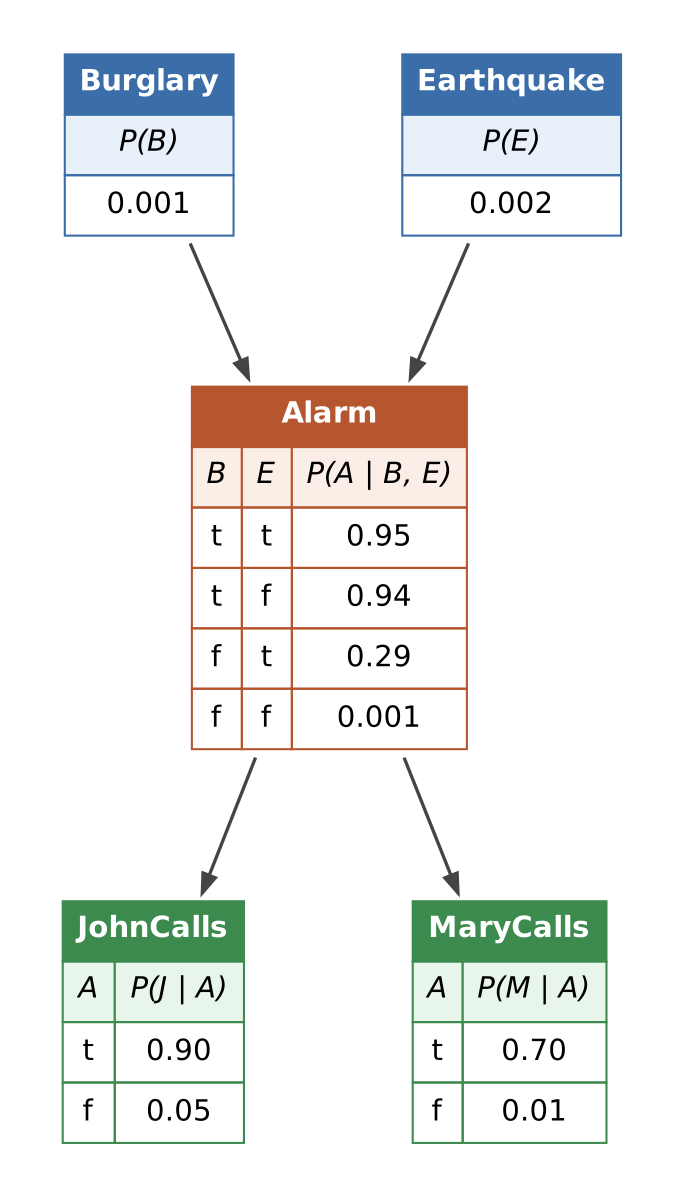

*The burglary network with its CPTs: each table gives the probability that the variable is true (t); the probability of false (f)*

In pyAgrum we build the **structure** with `gum.fastBN`, writing the arcs as a string. `Burglary{no|yes}` creates a variable with the two values `no` and `yes`.

BN{nodes: 5, arcs: 4, domainSize: 32, dim: 10, mem: 160o}


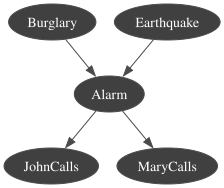

In [45]:
bn = gum.fastBN("Burglary{no|yes}->Alarm{no|yes}<-Earthquake{no|yes};"
                "Alarm->JohnCalls{no|yes};"
                "Alarm->MaryCalls{no|yes}")
print(bn)
show_bn(bn, size="4")

`fastBN` fills the CPTs with random numbers: now we write the real ones.
- A node **without parents** has a single distribution: `fillWith([P(no), P(yes)])`.
- A node **with parents** has one distribution for each combination of the parents' values: we select the row with a dictionary `{parent: value}` and assign `[P(no), P(yes)]`.

Each row must sum to 1.

In [46]:
bn.cpt("Burglary").fillWith([0.999, 0.001])
bn.cpt("Earthquake").fillWith([0.998, 0.002])

bn.cpt("Alarm")[{"Burglary": "yes", "Earthquake": "yes"}] = [0.05, 0.95]
bn.cpt("Alarm")[{"Burglary": "yes", "Earthquake": "no"}]  = [0.06, 0.94]
bn.cpt("Alarm")[{"Burglary": "no",  "Earthquake": "yes"}] = [0.71, 0.29]
bn.cpt("Alarm")[{"Burglary": "no",  "Earthquake": "no"}]  = [0.999, 0.001]

bn.cpt("JohnCalls")[{"Alarm": "yes"}] = [0.10, 0.90]
bn.cpt("JohnCalls")[{"Alarm": "no"}]  = [0.95, 0.05]

bn.cpt("MaryCalls")[{"Alarm": "yes"}] = [0.30, 0.70]
bn.cpt("MaryCalls")[{"Alarm": "no"}]  = [0.99, 0.01]

gnb.sideBySide(bn.cpt("Burglary"), bn.cpt("Earthquake"), bn.cpt("Alarm"),
               bn.cpt("JohnCalls"), bn.cpt("MaryCalls"))

## 1.2 Reading the CPTs and the chain rule

To read a single number we index the CPT with a dictionary that gives a value to the variable **and** to all its parents. The helper functions below are used in the rest of the notebook.

In [47]:
def parents(bn, var):
    "Names of the parents of var."
    return [bn.variable(p).name() for p in bn.parents(var)]

def children(bn, var):
    "Names of the children of var."
    return [bn.variable(c).name() for c in bn.children(var)]

def values(bn, var):
    "Possible values of var, e.g. ['no', 'yes']."
    return list(bn.variable(var).labels())

def topological_order(bn):
    "Variable names with the parents always before their children."
    return [bn.variable(i).name() for i in bn.topologicalOrder()]

def P(bn, var, value, assignment):
    "P(var = value | parents), reading the parents' values from the dictionary assignment." #compute probability (see the examples below)
    index = {var: value}
    for p in parents(bn, var):
        index[p] = assignment[p]
    return bn.cpt(var)[index]


print("Parents of Alarm:", parents(bn, "Alarm"), "  children:", children(bn, "Alarm"))
print("Topological order:", topological_order(bn))
print("P(Alarm=yes | Burglary=no, Earthquake=no) =", P(bn, "Alarm", "yes", {"Burglary": "no", "Earthquake": "no"}))

Parents of Alarm: ['Burglary', 'Earthquake']   children: ['JohnCalls', 'MaryCalls']
Topological order: ['Earthquake', 'Burglary', 'Alarm', 'MaryCalls', 'JohnCalls']
P(Alarm=yes | Burglary=no, Earthquake=no) = 0.001


With the chain rule we can compute the probability of a **complete** assignment, that is a value for every variable. For example, the probability that the alarm rings and both John and Mary call, but there is neither a burglary nor an earthquake:

$$P(j, m, a, \neg b, \neg e) = P(j \mid a)\, P(m \mid a)\, P(a \mid \neg b, \neg e)\, P(\neg b)\, P(\neg e) = 0.90 \times 0.70 \times 0.001 \times 0.999 \times 0.998 \approx 0.000628$$

In [48]:
def joint_probability(bn, assignment):
    "Chain rule: product of P(x_i | parents(X_i)) for all the variables."
    p = 1.0
    for var in bn.names():
        p *= P(bn, var, assignment[var], assignment)
    return p

x = {"Burglary": "no", "Earthquake": "no", "Alarm": "yes", "JohnCalls": "yes", "MaryCalls": "yes"}
print("By hand:  ", joint_probability(bn, x))


# Using pyAgrum functionalities

inst = bn.completeInstantiation()           # pyAgrum does the same with an Instantiation instead of the dictionary
for var, val in x.items():
    inst.chgVal(var, val)
print("pyAgrum:  ", bn.jointProbability(inst))

By hand:   0.0006281112599999999
pyAgrum:   0.00062811126


## 1.3 Exercise 1: build the sprinkler network

Complete the function `build_sprinkler` so that it builds and returns the network below, which we will use in Part 2. Its variables are `Cloudy`, `Sprinkler`, `Rain` and `WetGrass`, all with values `no` and `yes`:

```
          Cloudy
         /      \
   Sprinkler    Rain
         \      /
         WetGrass
```

<table>
<tr><th>CPT</th><th>parents' values</th><th>value</th></tr>
<tr><td>P(Cloudy)</td><td>–</td><td>0.5</td></tr>
<tr><td rowspan="2">P(Sprinkler | Cloudy)</td><td>c</td><td>0.10</td></tr>
<tr><td>¬c</td><td>0.50</td></tr>
<tr><td rowspan="2">P(Rain | Cloudy)</td><td>c</td><td>0.80</td></tr>
<tr><td>¬c</td><td>0.20</td></tr>
<tr><td rowspan="4">P(WetGrass | Sprinkler, Rain)</td><td>s, r</td><td>0.99</td></tr>
<tr><td>s, ¬r</td><td>0.90</td></tr>
<tr><td>¬s, r</td><td>0.90</td></tr>
<tr><td>¬s, ¬r</td><td>0.00</td></tr>
</table>

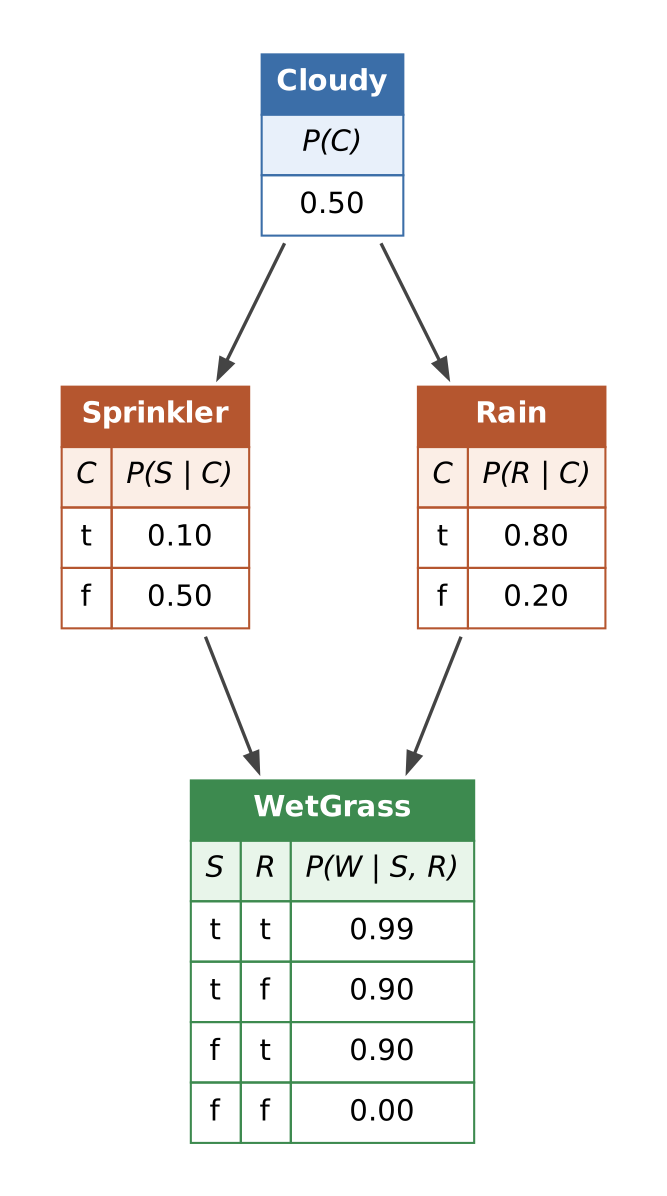

*The sprinkler network with its CPTs: each table gives the probability that the variable is true (t); the probability of false (f)*

**Steps**
0. Delete the `raise NotImplementedError(...)` line.
1. Create the structure with `gum.fastBN`: four arcs, separated by `;` (or written as chains such as `A->B->C`).
2. Fill the CPT of `Cloudy` with `fillWith`.
3. Fill the CPTs of `Sprinkler`, `Rain` and `WetGrass` row by row, with a dictionary for the parents.

**Hints**
- The values are always written as `[P(no), P(yes)]`: for example $P(Sprinkler = yes \mid Cloudy = yes) = 0.10$ becomes `[0.90, 0.10]`.
- `WetGrass` has two parents, so it has four rows.

When you are done, run `sprinkler = build_sprinkler()`: then `joint_probability(sprinkler, {"Cloudy": "yes", "Sprinkler": "no", "Rain": "yes", "WetGrass": "yes"})` should be $0.5 \times 0.9 \times 0.8 \times 0.9 = 0.324$.

In [62]:
def build_sprinkler():
    # TODO: structure (4 arcs)
    sprinkler = gum.fastBN("Cloudy{no|yes} -> Sprinkler{no|yes};"
                           "Cloudy{no|yes} -> Rain{no|yes};"
                           "Sprinkler{no|yes} -> WetGrass{no|yes};"
                           "Rain{no|yes} -> WetGrass{no|yes}")

    # TODO: CPT of Cloudy
    sprinkler.cpt("Cloudy").fillWith([0.50, 0.50])
    
    # TODO: CPT of Sprinkler (2 rows)
    sprinkler.cpt("Sprinkler")[{"Cloudy": "yes"}] = [0.90, 0.10]
    sprinkler.cpt("Sprinkler")[{"Cloudy": "no"}] = [0.50, 0.50]
    
    # TODO: CPT of Rain (2 rows)
    sprinkler.cpt("Rain")[{"Cloudy": "yes"}] = [0.20, 0.80]
    sprinkler.cpt("Rain")[{"Cloudy": "no"}] = [0.80, 0.20]
    
    # TODO: CPT of WetGrass (4 rows)
    sprinkler.cpt("WetGrass")[{"Sprinkler": "yes", "Rain": "yes"}] = [0.01, 0.99]
    sprinkler.cpt("WetGrass")[{"Sprinkler": "yes", "Rain": "no"}] = [0.10, 0.90]
    sprinkler.cpt("WetGrass")[{"Sprinkler": "no", "Rain": "yes"}] = [0.10, 0.90]
    sprinkler.cpt("WetGrass")[{"Sprinkler": "no", "Rain": "no"}] = [1.0, 0.0]
    
    gnb.sideBySide(sprinkler.cpt("Cloudy"), sprinkler.cpt("Sprinkler"), sprinkler.cpt("Rain"), sprinkler.cpt("WetGrass"))
    return sprinkler

P(c, ¬s, r, w) = 0.32400000000000007


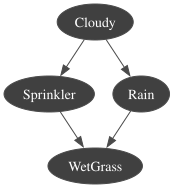

In [63]:
# compute the joint probability and display the bayesian network structure
# TODO: build the network with build_sprinkler() and store it in the variable sprinkler
sprinkler = build_sprinkler()

# TODO: print the joint probability of {"Cloudy": "yes", "Sprinkler": "no", "Rain": "yes", "WetGrass": "yes"}
assignment = {"Cloudy": "yes", "Sprinkler": "no", "Rain": "yes", "WetGrass": "yes"}
print("P(c, ¬s, r, w) =", joint_probability(sprinkler, assignment))

# TODO: draw the structure of the network with show_bn
show_bn(sprinkler)

# Part 2 — Bayesian network inference

## 2.1 Types of queries

Given the evidence $\mathbf{e}$ (the observed variables), the main inference queries are:

<table>
<tr><th>query</th><th>formula</th><th>question</th></tr>
<tr><td><b>marginal</b></td><td style="white-space:nowrap">P(X) = Σ<sub>y</sub> P(X, y)</td><td>how likely is each value of X, with no evidence?</td></tr>
<tr><td><b>posterior</b> (conditional)</td><td style="white-space:nowrap">P(X | e) = α Σ<sub>y</sub> P(X, e, y)</td><td>how likely is each value of X, given what we observed?</td></tr>
<tr><td><b>probability of the evidence</b></td><td style="white-space:nowrap">P(e) = Σ<sub>y</sub> P(e, y)</td><td>how likely is what we observed?</td></tr>
</table>

$\mathbf{Y}$ are the **hidden** variables, which we sum out, and $\alpha = 1/P(\mathbf{e})$ is the **normalization constant**.

The classic query of the book: *John and Mary both call. What is the probability of a burglary?*

**How to ask a query in pyAgrum.** Queries are answered by an **inference engine**, an object that runs an inference algorithm on the network. Here we use `gum.LazyPropagation`, the **default exact engine** of pyAgrum: we will see how it works in section 2.2 (it is based on the *junction tree*). Every engine is used in four steps:

```python
ie = gum.LazyPropagation(bn)     # 1. create the engine for the network bn
ie.setEvidence(evidence)         # 2. give the evidence, a dictionary {variable: observed value}
ie.makeInference()               # 3. run the inference
ie.posterior("Burglary")         # 4. read the posterior of a variable
```

After `makeInference()`, the same engine also gives the probability of the evidence with `ie.evidenceProbability()`. The function `exact_posterior`, defined in the cell below, wraps these steps and returns the posterior as a dictionary: we will use it to check the results of the other algorithms.

In [ ]:
evidence = {"JohnCalls": "yes", "MaryCalls": "yes"}

ie = gum.LazyPropagation(bn) # here is based on junction tree
ie.setEvidence(evidence)
ie.makeInference()

print("posterior   P(Burglary | j, m) =", ie.posterior("Burglary").tolist())
print("evidence    P(j, m)            =", round(ie.evidenceProbability(), 6))


def exact_posterior(bn, X, e):
    "Exact posterior P(X | e) as a dictionary {value: probability}, computed with LazyPropagation."
    ie = gum.LazyPropagation(bn)
    ie.setEvidence(e)
    ie.makeInference()
    return {x: ie.posterior(X)[{X: x}] for x in values(bn, X)}

Even if both neighbours call, the probability of a burglary is only **28%**: burglaries are very rare (0.1%) and the alarm can ring for other reasons.

`gnb.showInference` draws the network with the posterior distribution of **every** variable. The observed variables are coloured.

In [ ]:
show_inference(bn, evs={"JohnCalls": "yes", "MaryCalls": "yes"}, size="7")

## 2.2 Exact inference

**Inference** is the process of drawing conclusions from the available evidence. A probabilistic model can answer questions such as *what will probably happen if something else occurred?*, *what is the most likely explanation of an event?*, *how certain are we about a prediction?* Mathematically, this means computing the **posterior** $P(Y \mid \mathbf{x})$ of a query variable $Y$ given the observed evidence $\mathbf{x} = \{x_1, \dots, x_n\}$.

Exact inference computes it **exactly**. pyAgrum has three exact engines, used in the same way:

```python
ie = Engine(bn)               # gum.VariableElimination, gum.ShaferShenoyInference or gum.LazyPropagation
ie.setEvidence(evidence)      # what we observed
ie.makeInference()            # run the algorithm
ie.posterior("Burglary")      # read a posterior
```

### 2.2.1 Inference by enumeration

The simplest form of inference **marginalises** (sums out) the hidden variables of the joint distribution: this is *inference by enumeration*. In the burglary network, with evidence $j, m$:

$$P(b, j, m) = \sum_{e} \sum_{a} P(b, j, m, e, a) \qquad P(\neg b, j, m) = \sum_{e} \sum_{a} P(\neg b, j, m, e, a)$$

and then $P(B \mid j, m)$ is obtained by normalising. The problem is that **the same operations are repeated many times**: for example the products $P(j \mid a)\,P(m \mid a)$ are computed again for every value of $B$ and $E$. With $n$ boolean variables the cost is $O(2^n)$.

pyAgrum has no engine for enumeration, but we can reproduce it with operations on factors (`gum.Tensor`): multiply all the CPTs to build the **full joint table**, keep only the rows consistent with the evidence (`extract`), sum out the hidden variables (`sumIn` keeps only the query variable) and normalise.

In [ ]:
# full joint table: product of all the CPTs (chain rule)
joint = bn.cpt("Burglary") * bn.cpt("Earthquake") * bn.cpt("Alarm") * bn.cpt("JohnCalls") * bn.cpt("MaryCalls")
print("Entries of the joint table:", joint.domainSize(), "= 2^5")
print(joint)


evidence = {"JohnCalls": "yes", "MaryCalls": "yes"}
reduced = joint.extract(evidence)            # keep only the rows with JohnCalls = yes, MaryCalls = yes
print(reduced)
unnormalized = reduced.sumIn(["Burglary"])   # sum out the hidden variables Earthquake and Alarm: P(B, j, m) (i.e., all variables except the one declared in the list)
print("P(Burglary, j, m) =", unnormalized.tolist()) #the sum is different than one
print("P(Burglary | j, m) =", unnormalized.normalize().tolist()) # divide by the sum

The result is the same as `LazyPropagation` in section 2.1. But the joint table has $2^n$ entries: with 30 binary variables it would have more than a billion. Variable elimination avoids building it.

### 2.2.2 Variable elimination

**Variable elimination** computes the quantities of interest step by step, eliminating **one by one** the variables that are irrelevant to the query. In a Bayesian network each CPT is a **factor** $\Phi_X = P(X \mid Pa_X)$, and the joint distribution is their product. The key property is that a sum can be moved inside a product, past the factors that do not contain the summed variable:

$$\sum_X \Phi_1(A)\,\Phi_2(B) = \Phi_1(A) \sum_X \Phi_2(B) \qquad \text{if } X \text{ is not in the scope of } \Phi_1$$

For the burglary query this gives

$$P(B, j, m) = \sum_e \sum_a P(B)\,P(e)\,P(a \mid B, e)\,P(j \mid a)\,P(m \mid a) = P(B) \sum_e P(e) \underbrace{\sum_a P(a \mid B, e)\,P(j \mid a)\,P(m \mid a)}_{\tau(B,\,e)}$$

**Sum-product variable elimination.** For the query variables $Y$ the algorithm computes $\Phi^*(Y) = \sum_{Z} \prod_{\Phi} \Phi$: it selects a non-query variable $Z$ (in any order), computes the **product** of the factors involving it, and then **marginalises** (eliminates) it. The result is a new factor $\tau$, that replaces them. Above, eliminating $A$ creates $\tau(B, e)$; eliminating $E$ then leaves a factor over $B$ only.

**Elimination ordering.** A different order brings to the **same result**, but it can create much larger factors, and the cost depends on the size of the largest factor. Finding an optimal ordering is hard, but some practical **heuristics** can be used: pyAgrum chooses the order by itself.

**Evidence.** With evidence $Z = e$, $P(X \mid e) = P(X, e) / P(e) = P(X, e) / \alpha$. We simply perform variable elimination, but first **reduce** every factor that involves the evidence: $\Phi(X, Z' = e')$ becomes $\Phi(X, Z')[e']$, the factor without the entries not consistent with $e'$. At the end we normalise over $X$.

For example, the factor $P(JohnCalls \mid Alarm)$ reduced to the evidence $JohnCalls = yes$ keeps only one column: it becomes a factor over `Alarm` alone.

In pyAgrum variable elimination is the engine `gum.VariableElimination`:

In [ ]:

evidence = {"JohnCalls": "yes", "MaryCalls": "yes"}

ie = gum.VariableElimination(bn)
ie.setEvidence(evidence)
ie.makeInference()
print("P(Burglary | j, m) =", ie.posterior("Burglary").tolist())
ie.posterior("Burglary")

### 2.2.3 Belief propagation

**Belief propagation** is a family of exact inference algorithms based on **message passing**. In sum-product variable elimination, at each step a factor $\psi_i$ is created from the product of existing factors, and then a new factor $\tau_i$ is obtained by marginalisation. Graphically, we can see this as node $\psi_i$ **passing a message** $\tau_i$ to node $\psi_j$, which then passes a message $\tau_j$ to $\psi_k$, and so on:

$$\psi_i \xrightarrow{\;\tau_i\;} \psi_j \xrightarrow{\;\tau_j\;} \psi_k \;\cdots$$

**Clique tree.** This process builds a tree of clusters of variables, called **clique tree** (or **junction tree**):
- each cluster $C_i$ is the scope of a factor $\psi_i$;
- an edge between $C_i$ and $C_j$ is a message between them, associated with their intersection $C_i \cap C_j$, the **sepset**;
- the messages travel towards a **root** cluster that contains the query variable.

**Sum-product message passing.** Given a clique tree:
1. multiply the factors assigned to each cluster: these are the **initial potentials** $\psi_i$;
2. select any **root** cluster containing the query variable;
3. when it has received all the messages from its downstream neighbours, each cluster multiplies them by its potential, sums out the variables that are not in the sepset, and sends the result $\delta_{i \to j}$ to its upstream neighbour;
4. when all the messages have reached the root $C_r$, its **belief** $\beta_r(C_r)$ is proportional to the joint distribution of its variables: summing out the other variables gives the query.

**Calibration.** A message $\delta_{i \to j}$ depends only on the potential of $C_i$ and its incoming messages, not on the choice of the root. So each edge has only **two** messages, one per direction, and **two passes** are enough to compute all of them: **upward** from the leaves to any root, then **downward** from the root to the leaves. The clique tree is then **calibrated**, and the posterior of **any** variable can be read without recomputing anything.

In pyAgrum the clique tree engines are `gum.ShaferShenoyInference` and `gum.LazyPropagation` (the default engine, *lazy* because it only computes the messages that the query needs). After **one** call to `makeInference()` we can read the posterior of every variable:

In [ ]:
evidence = {"JohnCalls": "yes", "MaryCalls": "yes"}

ie = gum.LazyPropagation(bn)
ie.setEvidence(evidence)
ie.makeInference()                        # one inference: the clique tree is calibrated
for var in bn.names():
    print(f"P({var}=yes | j, m) = {ie.posterior(var)[{var: 'yes'}]:.4f}")

The three exact engines give the same posterior:

In [ ]:
for Engine in [gum.VariableElimination, gum.ShaferShenoyInference, gum.LazyPropagation]:
    ie = Engine(bn)
    ie.setEvidence(evidence)
    ie.makeInference()
    print(f"{Engine.__name__:<24}", ie.posterior("Burglary").tolist())

#### Exercise 2: exact inference on the sprinkler network

Compute $P(Rain = yes \mid WetGrass = yes)$ on the sprinkler network with each of the three exact algorithms of pyAgrum: **variable elimination** (`gum.VariableElimination`), the **junction tree** with Shafer-Shenoy (`gum.ShaferShenoyInference`) and the **junction tree** with lazy propagation (`gum.LazyPropagation`).

**Steps** (the same for each algorithm)
1. Create the inference engine for the network `sprinkler`, for example `ve = gum.VariableElimination(sprinkler)`.
2. Give the evidence with `setEvidence({"WetGrass": "yes"})`.
3. Run the inference with `makeInference()`.
4. Read the posterior of `Rain` with `posterior("Rain")`, and the probability of `yes` with `[{"Rain": "yes"}]`.

**Hints**
- `posterior("Rain")` returns the whole table $P(Rain \mid WetGrass = yes)$, with one probability for `no` and one for `yes`.
- Use a different variable name for each engine (for example `ve`, `ss` and `lp`).

When you are done, the three algorithms should all give $P(Rain = yes \mid WetGrass = yes) \approx 0.708$.

In [ ]:
# Variable elimination
# TODO: create a gum.VariableElimination engine for the sprinkler network
# TODO: give the evidence WetGrass = yes and run the inference
# TODO: print P(Rain = yes | WetGrass = yes)

# Junction tree (Shafer-Shenoy)
# TODO: the same steps with gum.ShaferShenoyInference

# Junction tree (lazy propagation)
# TODO: the same steps with gum.LazyPropagation

## 2.3 Approximate inference

The exact methods become problematic for **large** models, because of their computational complexity. Approximate inference gives reasonable answers in these cases.

The main idea is **probabilistic sampling**: draw $N$ samples from the probability distributions of the network, and from them derive the distribution of the query $P(X \mid \mathbf{e})$. As the number of samples grows, the approximation converges to the true distribution. Methods based on random sampling are called **Monte Carlo** algorithms. There are two classes:
- **direct sampling** methods: forward sampling, rejection sampling, likelihood weighting (for Bayesian networks);
- **Markov chain Monte Carlo** (MCMC) methods: Gibbs sampling (general).

We use the **burglary** network and the query of section 2.1, $P(Burglary \mid JohnCalls = yes, MaryCalls = yes)$, whose exact value is about 0.284. In pyAgrum every sampler is used like the exact engines; we also fix the number of samples $N$. The function below does it for us.

In [ ]:

evidence = {"JohnCalls": "yes", "MaryCalls": "yes"}

exact = exact_posterior(bn, "Burglary", evidence)["yes"]
print(f"Exact: P(Burglary=yes | j, m) = {exact:.3f}")

In [ ]:
def run_sampler(Engine, bn, evidence, N):
    "Run a pyAgrum sampler with exactly N samples and return the engine."
    ie = Engine(bn)              # create the sampler (e.g. gum.GibbsSampling) for the network bn
    ie.setEvidence(evidence)     # give the evidence, e.g. {"JohnCalls": "yes", "MaryCalls": "yes"}
    # define the stop parameters
    ie.setEpsilon(1e-9)          # stop rule 1: estimates change less than epsilon
    ie.setMinEpsilonRate(1e-9)   # stop rule 2: estimates improve too slowly
    ie.setMaxTime(30)            # stop after 30 seconds at most
    ie.setMaxIter(N)             # stop after N samples
    ie.setPeriodSize(N)          # check the stop rules only once, after N samples
    ie.makeInference()           # draw the samples and compute the estimates
    return ie                    # read the results with ie.posterior("Variable")


### 2.3.1 Forward sampling

**Forward** (or *prior*) sampling generates events from the network **without evidence**. Following the topological order `[Burglary, Earthquake, Alarm, JohnCalls, MaryCalls]`:
1. sample `Burglary` from $P(Burglary)$ → e.g. *no*;
2. sample `Earthquake` from $P(Earthquake)$ → e.g. *no*;
3. sample `Alarm` from $P(Alarm \mid Burglary = no, Earthquake = no)$ → e.g. *no*;
4. sample `JohnCalls` from $P(JohnCalls \mid Alarm = no)$ → e.g. *no*;
5. sample `MaryCalls` from $P(MaryCalls \mid Alarm = no)$ → e.g. *no*.

The sample is `[no, no, no, no, no]`. Repeating it many times, about 94% of the samples are this one, because $P(\neg b, \neg e, \neg a, \neg j, \neg m) = 0.999 \times 0.998 \times 0.999 \times 0.95 \times 0.99 \approx 0.937$.

With $N$ samples, the probability of an event is estimated by its frequency: $\hat P(\text{event}) = N_{\text{event}} / N$.

pyAgrum draws forward samples with `gum.BNDatabaseGenerator`. Let's estimate $P(JohnCalls = yes)$, whose exact value is about 0.052.

In [ ]:
generator = gum.BNDatabaseGenerator(bn)
generator.setVarOrder(["Burglary", "Earthquake", "Alarm", "JohnCalls", "MaryCalls"])
generator.drawSamples(10)
print(generator.to_pandas())

for N in [10, 1000, 100000]:
    generator.drawSamples(N)
    samples = generator.to_pandas()
    estimate = (samples["JohnCalls"] == "yes").mean()
    print(f"N = {N:>6}:  P(JohnCalls=yes) ≈ {estimate:.4f}   (exact {exact_posterior(bn, 'JohnCalls', {})['yes']:.4f})")

### 2.3.2 Rejection sampling

To compute $P(X \mid \mathbf{e})$, rejection sampling generates samples as before, but **counts only the samples consistent with the evidence** and rejects the others.

For our query, a sample is kept only if it has `JohnCalls = yes` **and** `MaryCalls = yes`. This evidence has probability about 0.002: out of 1000 samples, about 998 are **rejected**.

In pyAgrum it is `gum.MonteCarloSampling`. Here `N` is the number of **accepted** samples: to accept 500 of them, the sampler must draw about 250,000.

In [ ]:

evidence = {"JohnCalls": "yes", "MaryCalls": "yes"}

t0 = time.time()
ie = run_sampler(gum.MonteCarloSampling, bn, evidence, 500)
print(f"Rejection sampling: P(Burglary=yes | j, m) ≈ {ie.posterior('Burglary')[{'Burglary': 'yes'}]:.3f}"
      f"   (exact {exact:.3f}, {time.time() - t0:.1f} s)")

### 2.3.3 Likelihood weighting

Rejection sampling **wastes** a lot of samples. Likelihood weighting generates only samples **consistent with the evidence**: it fixes the evidence variables, samples only the others, and gives each sample a **weight** equal to the likelihood of the evidence.

For our query, `JohnCalls = yes` and `MaryCalls = yes` are fixed. Start with $w = 1$:
- `Burglary`, `Earthquake` and `Alarm` are not evidence: sample them, e.g. *no*, *no*, *yes*;
- `JohnCalls` is evidence: $w \leftarrow w \times P(j \mid a) = 0.9$;
- `MaryCalls` is evidence: $w \leftarrow w \times P(m \mid a) = 0.9 \times 0.7 = 0.63$.

If instead `Alarm` had been sampled *no*, the weight would be $P(j \mid \neg a) \times P(m \mid \neg a) = 0.05 \times 0.01 = 0.0005$: a sample that explains the evidence badly counts very little. The estimate sums the weights of the samples with `Burglary = yes` and normalises.

In pyAgrum it is `gum.WeightedSampling`.

In [ ]:

evidence = {"JohnCalls": "yes", "MaryCalls": "yes"}
ie = run_sampler(gum.WeightedSampling, bn, evidence, 10000)
print(f"Likelihood weighting: P(Burglary=yes | j, m) ≈ {ie.posterior('Burglary')[{'Burglary': 'yes'}]:.3f}   (exact {exact:.3f})")

With this evidence the estimate changes a lot from one run to another (run the cell again): the evidence is at the **bottom** of the network, so it cannot guide the sampling of the rare cause `Burglary`, and most samples have a tiny weight.

### 2.3.4 Gibbs sampling

The weights of likelihood weighting become smaller and smaller as the number of variables grows. **Markov chain Monte Carlo** (MCMC) methods do not sample from scratch every time: each sample is obtained by randomly changing the previous one (a *chain*).

**Gibbs sampling** starts from an arbitrary state consistent with the evidence, then repeatedly picks one **non-evidence** variable and samples it given its **Markov blanket**, keeping the others fixed. The Markov blanket of a variable is the set of its **parents**, its **children** and the **other parents of its children**: given these, the variable is independent of all the rest of the network.

For our query the non-evidence variables are `Burglary`, `Earthquake` and `Alarm`. Starting from `[¬b, ¬e, a, j, m]`:
- sample `Burglary` given its Markov blanket $\{Alarm, Earthquake\}$, from $P(Burglary \mid a, \neg e)$ → e.g. *yes*: the state becomes `[b, ¬e, a, j, m]`;
- sample `Alarm` given its Markov blanket $\{Burglary, Earthquake, JohnCalls, MaryCalls\}$ → e.g. *yes*: the state stays `[b, ¬e, a, j, m]`;
- and so on. The estimate is the fraction of states with `Burglary = yes`.

Since the evidence stays fixed along the whole chain, rare evidence is not a problem. In pyAgrum it is `gum.GibbsSampling`.

In [ ]:
evidence = {"JohnCalls": "yes", "MaryCalls": "yes"}
ie = run_sampler(gum.GibbsSampling, bn, evidence, 10000)
print(f"Gibbs sampling: P(Burglary=yes | j, m) ≈ {ie.posterior('Burglary')[{'Burglary': 'yes'}]:.3f}   (exact {exact:.3f})")

#### Exercise 3: approximate inference on the sprinkler network

Use the four approaches on the **sprinkler** network, with the queries of the slides, and compare each estimate with the exact value (`exact_posterior`):

<table>
<tr><th>approach</th><th>pyAgrum engine</th><th>query</th></tr>
<tr><td>forward sampling</td><td><code>gum.BNDatabaseGenerator</code></td><td style="white-space:nowrap">P(Cloudy = true, Rain = true)</td></tr>
<tr><td>rejection sampling</td><td><code>gum.MonteCarloSampling</code></td><td style="white-space:nowrap">P(Rain = true | Sprinkler = true)</td></tr>
<tr><td>likelihood weighting</td><td><code>gum.WeightedSampling</code></td><td style="white-space:nowrap">P(Rain = true | Cloudy = true, WetGrass = true)</td></tr>
<tr><td>Gibbs sampling</td><td><code>gum.GibbsSampling</code></td><td style="white-space:nowrap">P(Rain = true | Sprinkler = true, WetGrass = true)</td></tr>
</table>

In the code, *true* corresponds to the value <code>"yes"</code> and *false* to <code>"no"</code>.

**Steps**
1. Forward sampling: draw `N` samples with `gum.BNDatabaseGenerator(sprinkler)` and count the fraction with `Cloudy == "yes"` and `Rain == "yes"`, as in section 2.3.1.
2. The other three: run `run_sampler(Engine, sprinkler, evidence, N)` with the right engine and evidence, and read `posterior("Rain")[{"Rain": "yes"}]`.
3. Repeat with `N` = 10, 100, 1,000 and 10,000. What happens to the error when $N$ grows?

In [ ]:
# TODO: forward sampling: estimate P(Cloudy=yes, Rain=yes) with gum.BNDatabaseGenerator(sprinkler)
# TODO: rejection sampling: estimate P(Rain=yes | Sprinkler=yes) with gum.MonteCarloSampling
# TODO: likelihood weighting: estimate P(Rain=yes | Cloudy=yes, WetGrass=yes) with gum.WeightedSampling
# TODO: Gibbs sampling: estimate P(Rain=yes | Sprinkler=yes, WetGrass=yes) with gum.GibbsSampling
# TODO: compare each estimate with the exact value, for N = 10, 100, 1000, 10000